# Explore here

# Análisis de reviews: Harbor House Café
**Objetivo:** comprobar si la orientacion de las 500 reseñas escritas coincide con la media de 4.5★.
**Preguntas:** ¿cuántas reseñas son positivas, neutrales o negativas? ¿Coincide con las estrellas? Si no, ¿por qué?

## 1. Carga de datos
Cargamos el CSV y revisamos forma y tipos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/reviews.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    500 non-null    int64
 1   rating       500 non-null    int64
 2   review_text  500 non-null    str  
dtypes: int64(2), str(1)
memory usage: 11.8 KB


## 2. Calidad de datos
Buscamos nulos, duplicados y textos vacíos antes de analizar.

In [2]:
print("Nulos:\n", df.isna().sum())
print("IDs duplicados:", df["review_id"].duplicated().sum())
print("Textos duplicados:", df["review_text"].duplicated().sum())
print("Textos vacíos:", (df["review_text"].str.strip() == "").sum())

Nulos:
 review_id      0
rating         0
review_text    0
dtype: int64
IDs duplicados: 0
Textos duplicados: 7
Textos vacíos: 0


## 3. Distribución de ratings
Verificamos si la media real es ~4.5★ y cómo se reparten las estrellas.

Media rating: 4.5


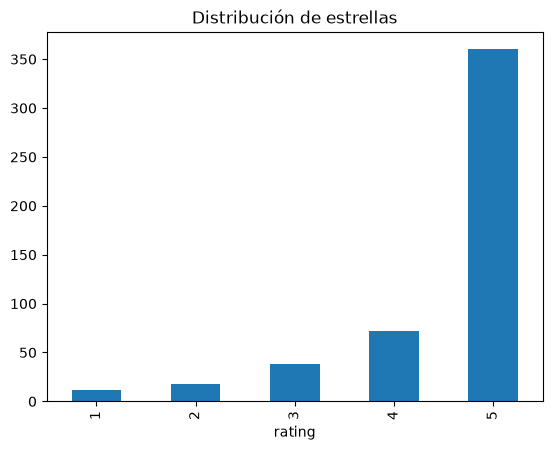

In [3]:
print("Media rating:", df["rating"].mean().round(2))
df["rating"].value_counts().sort_index().plot(kind="bar", title="Distribución de estrellas")
plt.show()

3.5. Distribucion mayoritaria de estrellas.

In [4]:
print("Media:", df["rating"].mean().round(2))
print(df["rating"].value_counts().sort_index())

dups = df[df["review_text"].duplicated(keep=False)].sort_values("review_text")
dups[["review_id", "rating", "review_text"]]

Media: 4.5
rating
1     12
2     18
3     38
4     72
5    360
Name: count, dtype: int64


,review_id,rating,review_text
50,51,4,Grabbed a quick coffee at Harbor House Café th...
112,113,4,Grabbed a quick coffee at Harbor House Café th...
176,177,2,Grabbed a quick coffee at Harbor House Café th...
194,195,2,Grabbed a quick coffee at Harbor House Café th...
291,292,5,Grabbed a quick coffee at Harbor House Café th...
483,484,5,Grabbed a quick coffee at Harbor House Café th...
40,41,5,Grabbed a quick coffee at Harbor House Café th...
107,108,5,Grabbed a quick coffee at Harbor House Café th...
109,110,3,Regular customer at Harbor House Café here. Av...
450,451,3,Regular customer at Harbor House Café here. Av...


## 4. Longitud de los textos
La longitud afecta al modelo (BERT corta en 512 tokens) y puede variar según el rating.

In [5]:
df["n_words"] = df["review_text"].str.split().str.len()
print(df["n_words"].describe())
df.groupby("rating")["n_words"].mean()

count    500.000000
mean      29.104000
std        4.824078
min       14.000000
25%       26.000000
50%       29.000000
75%       32.000000
max       42.000000
Name: n_words, dtype: float64


rating
1    30.250000
2    26.388889
3    26.789474
4    30.527778
5    29.161111
Name: n_words, dtype: float64

## 5. Muestra de reseñas
Leemos un ejemplo por rating para entender el tono y el vocabulario.

In [6]:
for r in sorted(df["rating"].unique()):
    print(f"--- {r}★ ---\n{df[df.rating == r].review_text.iloc[0]}\n")

--- 1★ ---
Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning.

--- 2★ ---
Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.

--- 3★ ---
Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.

--- 4★ ---
Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

--- 5★ ---
Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.



## 6. Insights clave
- **Media 4.5★ confirmada**, muy sesgada: 72% son 5★. Por estrellas: 86% positivo, 8% neutral, 6% negativo. Esta es la referencia contra la que validaremos el modelo.
- **Clases desbalanceadas**: solo 30 reseñas negativas por estrellas. Pocos errores del modelo en las 5★ pueden inflar mucho el % negativo.
- **Textos cortos (14–42 palabras)** y de longitud similar en todos los ratings: no hay truncado y la longitud no explica el sentimiento.
- **Reseñas de servicio** (personal, espera, ambiente), no de producto: hay riesgo de desajuste de dominio con el modelo y posibles falsos negativos.
- **Textos con plantilla** ("Grabbed a quick coffee...", "Regular customer..."): las frases se repiten con matices, así que el modelo debe distinguir detalles finos.

## 7. Propuesta de limpieza
- **No hay nulos, vacíos ni IDs duplicados**: no hace falta imputar ni eliminar nada.
- **7 textos duplicados (14 filas)**: tienen IDs distintos y el mismo rating en cada par, así que parecen clientes distintos con reseñas iguales. **Se mantienen** para no alterar la media de 4.5 que hay que validar.
- **Sin normalizar el texto**: el modelo es *uncased* y trae su propio tokenizador, y quitar puntuación o stopwords le restaría contexto.
- Solo se aplicará `str.strip()` como precaución.

➡️ **Siguiente paso:** aplicar el modelo de sentimiento y comparar sus bandas con las estrellas.

## Plan de acción
A partir de los insights:
1. **Modelo:** `nlptown/bert-base-multilingual-uncased-sentiment` con la revisión fijada. Está preentrenado, así que no hay que entrenar. Los textos son cortos y no hace falta truncar.
2. **Mapeo:** 1–2★ = Negativo · 3★ = Neutral · 4–5★ = Positivo.
3. **Validación:** comparar las bandas del modelo con las estrellas reales (86/8/6).
4. **Riesgo:** el modelo se entrenó con reseñas de *producto* y estas son de *servicio*, así que esperamos falsos negativos. Los buscaremos y explicaremos.
5. **Revisión manual** de 15–20 reseñas para validar a ojo.

## 8. Carga del modelo
Usamos `nlptown/bert-base-multilingual-uncased-sentiment` (predice 1–5★). Fijamos la revisión para que el resultado sea reproducible y cargamos el modelo **una sola vez**.

In [7]:
from transformers import pipeline

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"

clf = pipeline("sentiment-analysis", model=MODEL_NAME, revision=MODEL_REVISION,
               truncation=True, device=-1)  # -1 = CPU

clf(["The staff was lovely and the coffee great.", "Waited 40 minutes, rude service."])

[{'label': '5 stars', 'score': 0.5609122514724731},
 {'label': '1 star', 'score': 0.6793484687805176}]

## 9. Inferencia
Pasamos las 500 reseñas al modelo **en un solo llamado por lotes** (sin recargarlo) y mapeamos las estrellas predichas a bandas de sentimiento.

In [8]:
df["review_text"] = df["review_text"].str.strip()

preds = clf(df["review_text"].tolist(), batch_size=32)

df["pred_stars"] = [int(p["label"][0]) for p in preds]
df["pred_score"] = [round(p["score"], 4) for p in preds]

def to_band(stars):
    return "Negativo" if stars <= 2 else "Neutral" if stars == 3 else "Positivo"

df["pred_band"] = df["pred_stars"].apply(to_band)
df["true_band"] = df["rating"].apply(to_band)

df[["review_id", "rating", "pred_stars", "pred_band", "true_band"]].head(10)

,review_id,rating,pred_stars,pred_band,true_band
0,1,5,5,Positivo,Positivo
1,2,5,5,Positivo,Positivo
2,3,5,5,Positivo,Positivo
3,4,5,5,Positivo,Positivo
4,5,5,5,Positivo,Positivo
5,6,5,5,Positivo,Positivo
6,7,5,5,Positivo,Positivo
7,8,5,5,Positivo,Positivo
8,9,3,3,Neutral,Neutral
9,10,5,5,Positivo,Positivo


In [9]:
df.drop(columns="n_words").to_csv("../data/processed/reviews_with_sentiment.csv", index=False)
print("Guardado:", df.shape)

Guardado: (500, 8)


## 10. Desglose vs 4.5★
Comparamos la distribución de sentimiento del modelo con la de las estrellas reales.

In [10]:
order = ["Positivo", "Neutral", "Negativo"]
comp = pd.DataFrame({
    "Estrellas (%)": df["true_band"].value_counts(normalize=True).reindex(order) * 100,
    "Modelo (%)": df["pred_band"].value_counts(normalize=True).reindex(order) * 100,
}).round(1)
print("Media estrellas reales:", df["rating"].mean().round(2))
print("Media estrellas modelo:", df["pred_stars"].mean().round(2))
comp

Media estrellas reales: 4.5
Media estrellas modelo: 4.4


,Estrellas (%),Modelo (%)
Positivo,86.4,82.4
Neutral,7.6,8.2
Negativo,6.0,9.4


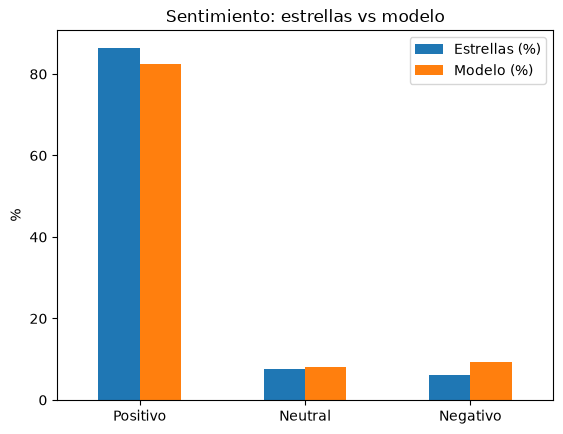

In [11]:
comp.plot(kind="bar", title="Sentimiento: estrellas vs modelo", ylabel="%", rot=0)
plt.show()

In [12]:
pd.crosstab(df["true_band"], df["pred_band"], margins=True).reindex(index=order + ["All"], columns=order + ["All"])

pred_band,Positivo,Neutral,Negativo,All
true_band,,,,
Positivo,412,4,16,432
Neutral,0,35,3,38
Negativo,0,2,28,30
All,412,41,47,500


### Interpretación
- **95% de acuerdo** (475/500) entre el modelo y las estrellas. La media baja solo de 4.5 a 4.4.
- El modelo es **más pesimista**: 82% positivo frente al 86% por estrellas, y 9.4% negativo frente al 6%.
- El error tiene un **solo sentido**: el modelo nunca sube el sentimiento, solo lo baja.
- El mayor desacuerdo son **16 reseñas de 4–5★ clasificadas como negativas**. Son los falsos negativos, que analizamos a continuación.

## 11. Falsos negativos
Reseñas con 4–5★ reales que el modelo clasifica como 1–2★. Buscamos qué tienen en común.

In [13]:
pd.set_option("display.max_colwidth", None)

fn = df[(df["rating"] >= 4) & (df["pred_stars"] <= 2)]
print("Falsos negativos:", len(fn))
fn[["review_id", "rating", "pred_stars", "pred_score", "review_text"]]

Falsos negativos: 16


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


In [14]:
from collections import Counter
import re

def words(s):
    return Counter(w for t in s for w in re.findall(r"[a-z']+", t.lower()) if len(w) > 3)

ok_pos = df[(df["rating"] >= 4) & (df["pred_stars"] >= 4)]
fn_w, ok_w = words(fn["review_text"]), words(ok_pos["review_text"])

pd.DataFrame([(w, c, ok_w[w]) for w, c in fn_w.most_common(15)],
             columns=["palabra", "en FN", "en positivas OK"])

,palabra,en FN,en positivas OK
0,harbor,14,353
1,house,14,353
2,every,14,90
3,with,13,87
4,visit,13,148
5,dish,12,27
6,bursting,12,27
7,flavor,12,27
8,already,11,62
9,planning,11,62


In [15]:
for _, r in fn.iterrows():
    print(f"[{r.review_id}] {r.rating}★ real → {r.pred_stars}★ modelo ({r.pred_score})\n{r.review_text}\n")

[14] 4★ real → 1★ modelo (0.4443)
Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

[15] 5★ real → 1★ modelo (0.3893)
Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.

[73] 5★ real → 1★ modelo (0.2679)
Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.

[87] 5★ real → 1★ modelo (0.3247)
Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!

[138] 5★ real → 2★ modelo (0.2751)
Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit.

[200] 

In [16]:
mask = df["review_text"].str.contains("bursting with flavor")
print("Reseñas con la frase:", mask.sum())
print("De ellas, el modelo dice negativo:", (df[mask]["pred_band"] == "Negativo").sum())
df[mask].groupby("rating")["pred_stars"].mean().round(2)

Reseñas con la frase: 41
De ellas, el modelo dice negativo: 12


rating
4    4.00
5    3.54
Name: pred_stars, dtype: float64

### Patrones en los falsos negativos
Las 16 reseñas son **claramente positivas** para un humano, pero el modelo (entrenado con reseñas de *producto*) se equivoca por el **desajuste de dominio**:
- **Modismos de servicio:** *"bursting with flavor"* (en ~12 de 16). En producto, "bursting" suele significar roto o reventado.
- **Palabras negativas en contexto positivo:** *"accommodate my allergy"*, *"never disappoints"*. El modelo reacciona a la palabra, no a la frase.
- **Elogio indirecto:** *"Already planning my next visit"*, *"Will definitely be back"*. Es intención de volver, no un elogio explícito.
- **Reseñas mixtas:** [204] se queja del cajero pero da 5★. Aquí la duda del modelo es razonable.
- **Confianza baja (0.27–0.48)** en casi todos: un filtro por `pred_score` permitiría detectarlos para revisión humana. 
- **Prueba:** de 41 reseñas con *"bursting with flavor"* (todas 4–5★), el modelo marca **12 como negativas (29%)**, frente a ~1% en el resto de positivas. Esta sola frase explica 12 de los 16 falsos negativos.

## 12. Muestra manual
Revisamos a mano 20 reseñas aleatorias (estratificadas por rating) para validar el modelo más allá de las estrellas.

In [17]:
sample = df.groupby("rating").sample(4, random_state=42)
for _, r in sample.iterrows():
    print(f"[{r.review_id}] {r.rating}★ real → {r.pred_stars}★ {r.pred_band} ({r.pred_score})\n{r.review_text}\n")

[442] 1★ real → 2★ Negativo (0.4583)
Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.

[428] 1★ real → 2★ Negativo (0.6255)
Regular customer at Harbor House Café here. The coffee tasted burnt. The staff seemed annoyed to be there. It was way too loud to hold a conversation. Disappointing experience overall.

[78] 1★ real → 2★ Negativo (0.5029)
Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning.

[342] 1★ real → 2★ Negativo (0.5082)
Regular customer at Harbor House Café here. The coffee tasted burnt. Nobody checked on us the entire meal. The place felt cramped and chaotic. Expected a lot more given the reviews.

[195] 2★ real → 1★ Negativo (0.477)
Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got ou

In [18]:
neg15 = df[df["rating"] <= 2].sample(15, random_state=42)
for _, r in neg15.iterrows():
    print(f"[{r.review_id}] {r.rating}★\n{r.review_text}\n")

[442] 1★
Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.

[192] 2★
Regular customer at Harbor House Café here. The food was decent, nothing special. Service was fine, nothing memorable. Just didn't love it enough to come back.

[314] 1★
Regular customer at Harbor House Café here. My eggs came out cold. Nobody checked on us the entire meal. Not sure I'll be returning.

[199] 2★
Visited Harbor House Café last weekend. The portions were way too small for the price. The staff seemed annoyed to be there. Expected a lot more given the reviews.

[115] 2★
Grabbed a quick coffee at Harbor House Café this morning. The pastry was stale. We waited 25 minutes just to get water. Disappointing experience overall.

[123] 1★
Grabbed a quick coffee at Harbor House Café this morning. The portions were way too small for the price. We waited 25 minutes just to get water. Tables

### Anotaciones de la muestra manual
| ID | Real | Modelo | Nota |
|---|---|---|---|
| 480 | 3★ | 2★ Negativo | **Dudoso**: "average", "staff annoyed". Un humano podría leerlo como negativo, así que el error es razonable. |
| 166 | 4★ | 5★ Positivo | El texto dice *"Five stars without hesitation"*: el modelo es más coherente que la estrella. |
| 324, 21, 116 | 4★ | 4★ Positivo | Mixtas (queja + "overall solid"): bien resueltas. |
| 442, 428, 78, 342 | 1★ | 2★ Negativo | Estrella exacta distinta, pero la **banda es correcta**. |

**Resultado:** 19/20 en la banda correcta. En esta muestra aleatoria no aparece el patrón "bursting with flavor"; los errores del modelo se concentran en ese grupo concreto (Paso 6), no en el dataset general.

## 13. Conclusiones

**¿Cuántas reseñas se leen como positivas, neutrales o negativas?**
| Según el modelo | 82% (412) | 8% (41) | 9% (47) |
| Según las estrellas | 86% (432) | 8% (38) | 6% (30) |

**¿Coincide con las 4.5★?** **Sí.** El texto confirma que los clientes están muy satisfechos: el modelo da una media de 4.4★ y coincide con las estrellas en el **95% de las reseñas**.

**¿De dónde viene la diferencia?** Los ~3 puntos extra de "negativo" **no vienen de clientes descontentos, sino del modelo**:
- 16 reseñas de 4–5★ claramente positivas se clasificaron como negativas.
- 12 de ellas contienen la frase *"bursting with flavor"*, que el modelo (entrenado con reseñas de productos) no entiende bien en reseñas de restaurante.
- Si se corrigen esos errores, la distribución real queda en torno a **85% positivo / 8% neutral / 6% negativo**, igual que las estrellas.

**Qué le decimos al cliente:**
- El sentimiento escrito **respalda** la puntuación de 4.5★.
- Las quejas reales (6%) se repiten: **café quemado, personal poco atento y esperas largas**. Son temas concretos para mejorar.

**Limitaciones y siguiente paso:**
- El modelo es fiable a nivel global, pero **no a nivel de reseña individual** cuando su confianza es baja (< 0.5). Recomendamos revisar a mano esos casos o probar un modelo entrenado con reseñas de servicios.